In [1]:

#Check the uploaded file
import pandas as pd

df = pd.read_csv('/content/202510-divvy-tripdata.csv')

print("Number of rows:", len(df))
print("Column names:")
print(df.columns.tolist())

Number of rows: 646039
Column names:
['ride_id', 'rideable_type', 'started_at', 'ended_at', 'start_station_name', 'start_station_id', 'end_station_name', 'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng', 'member_casual']


In [25]:
#Check the rider categories

print(df['member_casual'].value_counts())

member_casual
member    422029
casual    224010
Name: count, dtype: int64


In [3]:
#Calculate ride duration
#This calculates ride duration in minutes and shows us a summary, including the average and minimum and maximum values.
df['started_at'] = pd.to_datetime(df['started_at'])
df['ended_at'] = pd.to_datetime(df['ended_at'])

df['ride_length_minutes'] = (
    df['ended_at'] - df['started_at']
).dt.total_seconds() / 60

print(df['ride_length_minutes'].describe())

count    646039.000000
mean         15.174459
std          53.789841
min           0.002083
25%           5.194667
50%           8.969717
75%          15.645275
max        1499.965117
Name: ride_length_minutes, dtype: float64


In [4]:

#Count invalid ride durations
print("Zero or negative rides:",
      (df['ride_length_minutes'] <= 0).sum())

print("Rides longer than 24 hours:",
      (df['ride_length_minutes'] > 1440).sum())

print("Missing ride durations:",
      df['ride_length_minutes'].isna().sum())

Zero or negative rides: 0
Rides longer than 24 hours: 599
Missing ride durations: 0


In [5]:

#Create a cleaned October dataset
df_clean = df[df['ride_length_minutes'] <= 1440].copy()

print("Original rides:", len(df))
print("Rides excluded:", len(df) - len(df_clean))
print("Rides remaining:", len(df_clean))

Original rides: 646039
Rides excluded: 599
Rides remaining: 645440


In [6]:

#Compare ride duration by rider type
#This calculates the number of rides, average duration, and median duration for each rider type.
df_clean.groupby('member_casual')['ride_length_minutes'].agg(
    ['count', 'mean', 'median']
).round(2)


,count,mean,median
member_casual,,,
casual,223545,17.38,10.25
member,421895,11.90,8.42


In [7]:

#Compare rides by day of the week
df_clean['day_of_week'] = df_clean['started_at'].dt.day_name()

day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

weekday_counts = df_clean.groupby(
    ['day_of_week', 'member_casual']
).size().unstack(fill_value=0)

weekday_counts = weekday_counts.reindex(day_order)

print(weekday_counts)


member_casual  casual  member
day_of_week                  
Monday          22291   52752
Tuesday         18790   53814
Wednesday       27645   74543
Thursday        33444   79032
Friday          38731   69503
Saturday        44265   49966
Sunday          38379   42285


In [8]:

#Calculate weekday versus weekend totals
df_clean['day_type'] = df_clean['started_at'].dt.dayofweek.map(
    lambda day: 'Weekend' if day >= 5 else 'Weekday'
)

day_type_counts = df_clean.groupby(
    ['day_type', 'member_casual']
).size().unstack(fill_value=0)

print(day_type_counts)


member_casual  casual  member
day_type                     
Weekday        140901  329644
Weekend         82644   92251


In [9]:

#Calculate percentages
#This calculates the percentage of each rider group's rides that occurred on weekdays and weekends.
day_type_percent = day_type_counts.div(
    day_type_counts.sum(axis=0), axis=1
) * 100

print(day_type_percent.round(2))


member_casual  casual  member
day_type                     
Weekday         63.03   78.13
Weekend         36.97   21.87


In [10]:

#Check all 12 files in Colab
#This checks which CSV files Colab can see directly in /content without loading all the data into memory.
import os

csv_files = sorted([
    f for f in os.listdir('/content')
    if f.endswith('.csv') and 'divvy-tripdata' in f
])

print("Number of CSV files found:", len(csv_files))
print(csv_files)


Number of CSV files found: 12
['202501-divvy-tripdata.csv', '202510-divvy-tripdata.csv', '202511-divvy-tripdata.csv', '202512-divvy-tripdata.csv', '202602-divvy-tripdata.csv', '202603-divvy-tripdata.csv', '202604-divvy-tripdata.csv', '202605-divvy-tripdata.csv', '202606-divvy-tripdata.csv', '202607-divvy-tripdata.csv', '202608-divvy-tripdata.csv', '202609-divvy-tripdata.csv']


In [11]:
#Combine all 12 months
import pandas as pd
import os

folder = '/content'

csv_files = sorted([
    f for f in os.listdir(folder)
    if f.endswith('.csv') and 'divvy-tripdata' in f
])

dataframes = []

for file in csv_files:
    temp_df = pd.read_csv(os.path.join(folder, file))
    dataframes.append(temp_df)
    print(f"Loaded {file}: {len(temp_df):,} rows")

df_all = pd.concat(dataframes, ignore_index=True)

print("\nTotal rows across all 12 months:", f"{len(df_all):,}")
print("Total columns:", len(df_all.columns))
print("Rider categories:")
print(df_all['member_casual'].value_counts())


Loaded 202501-divvy-tripdata.csv: 137,787 rows
Loaded 202510-divvy-tripdata.csv: 646,039 rows
Loaded 202511-divvy-tripdata.csv: 356,628 rows
Loaded 202512-divvy-tripdata.csv: 140,534 rows
Loaded 202602-divvy-tripdata.csv: 201,450 rows
Loaded 202603-divvy-tripdata.csv: 317,037 rows
Loaded 202604-divvy-tripdata.csv: 448,252 rows
Loaded 202605-divvy-tripdata.csv: 653,704 rows
Loaded 202606-divvy-tripdata.csv: 762,550 rows
Loaded 202607-divvy-tripdata.csv: 869,051 rows
Loaded 202608-divvy-tripdata.csv: 868,191 rows
Loaded 202609-divvy-tripdata.csv: 770,562 rows

Total rows across all 12 months: 6,171,785
Total columns: 13
Rider categories:
member_casual
member    3982761
casual    2189024
Name: count, dtype: int64


In [12]:


#Verify the combined dataset
#This checks the row count, column names, rider categories, and missing values in four important columns.
print("Total rows:", f"{len(df_all):,}")
print("\nColumn names:")
print(df_all.columns.tolist())

print("\nRides by rider type:")
print(df_all['member_casual'].value_counts())

print("\nMissing values in key columns:")
print(
    df_all[['ride_id', 'started_at', 'ended_at', 'member_casual']]
    .isna()
    .sum()
)


Total rows: 6,171,785

Column names:
['ride_id', 'rideable_type', 'started_at', 'ended_at', 'start_station_name', 'start_station_id', 'end_station_name', 'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng', 'member_casual']

Rides by rider type:
member_casual
member    3982761
casual    2189024
Name: count, dtype: int64

Missing values in key columns:
ride_id          0
started_at       0
ended_at         0
member_casual    0
dtype: int64


In [13]:

#Check for duplicate ride IDs
print("Duplicate ride IDs:", df_all['ride_id'].duplicated().sum())
print("Missing ride IDs:", df_all['ride_id'].isna().sum())


Duplicate ride IDs: 35
Missing ride IDs: 0


In [14]:
#Check the duplicate records
#This displays every row involved in a repeated ride ID, including the original occurrence, so we can see whether the records are exact duplicates or whether the same ID has different details.
duplicate_rows = df_all[df_all['ride_id'].duplicated(keep=False)]

print("Rows involved in duplicate IDs:", len(duplicate_rows))
print("\nSample duplicate records:")
display(duplicate_rows.sort_values('ride_id').head(10))


Rows involved in duplicate IDs: 70

Sample duplicate records:


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
2043588,03C5375398BE0649,electric_bike,2026-04-30 23:46:36.039,2026-05-01 00:04:48.512,NaN,NaN,Clark St & Arlington Pl,CHI02109,41.900000,-87.630000,41.926940,-87.641480,member
2784442,03C5375398BE0649,electric_bike,2026-04-30 23:46:36.039,2026-05-01 00:04:48.512,NaN,NaN,Clark St & Arlington Pl,CHI02109,41.900000,-87.630000,41.926940,-87.641480,member
2164920,0612B2A21BA5E988,classic_bike,2026-04-30 15:56:11.305,2026-05-01 16:56:08.148,Fulton Market,CHI01880,NaN,NaN,41.886871,-87.648089,NaN,NaN,member
2507501,0612B2A21BA5E988,classic_bike,2026-04-30 15:56:11.305,2026-05-01 16:56:08.148,Fulton Market,CHI01880,NaN,NaN,41.886871,-87.648089,NaN,NaN,member
2399509,10117825A92C182D,classic_bike,2026-04-30 23:56:24.321,2026-05-01 00:01:51.860,Peoria St & Kinzie St,CHI02098,Ogden Ave & Chicago Ave,CHI00275,41.888960,-87.649730,41.896362,-87.654061,casual
1984147,10117825A92C182D,classic_bike,2026-04-30 23:56:24.321,2026-05-01 00:01:51.860,Peoria St & Kinzie St,CHI02098,Ogden Ave & Chicago Ave,CHI00275,41.888960,-87.649730,41.896362,-87.654061,casual
1916337,15521787039F37E5,classic_bike,2026-04-30 23:54:44.934,2026-05-01 00:05:45.575,Michigan Ave & 11th St,CHI02025,DuSable Lake Shore Dr & Monroe St,CHI00374,41.869590,-87.623961,41.880958,-87.616743,member
2665751,15521787039F37E5,classic_bike,2026-04-30 23:54:44.934,2026-05-01 00:05:45.575,Michigan Ave & 11th St,CHI02025,DuSable Lake Shore Dr & Monroe St,CHI00374,41.869590,-87.623961,41.880958,-87.616743,member
2175260,1DB04E901469FB2F,electric_bike,2026-04-30 23:54:09.726,2026-05-01 00:11:09.709,Ravenswood Ave & Irving Park Rd,CHI00309,NaN,NaN,41.954690,-87.673930,41.970000,-87.670000,casual
2864191,1DB04E901469FB2F,electric_bike,2026-04-30 23:54:09.726,2026-05-01 00:11:09.709,Ravenswood Ave & Irving Park Rd,CHI00309,NaN,NaN,41.954690,-87.673930,41.970000,-87.670000,casual


In [15]:

#Check for exact duplicate rows
#This checks whether entire rows are repeated exactly—not just whether their ride IDs match.
print(
    "Exact duplicate rows:",
    df_all.duplicated().sum()
)


Exact duplicate rows: 35


In [16]:

#Remove exact duplicate rows
#This preserves your original df_all dataset and creates a cleaned copy named df_all_clean.
df_all_clean = df_all.drop_duplicates().copy()

print("Rows before removing exact duplicates:", f"{len(df_all):,}")
print("Rows after removing exact duplicates:", f"{len(df_all_clean):,}")
print("Exact duplicate rows remaining:", df_all_clean.duplicated().sum())
print(
    "Duplicate ride IDs remaining:",
    df_all_clean['ride_id'].duplicated().sum()
)


Rows before removing exact duplicates: 6,171,785
Rows after removing exact duplicates: 6,171,750
Exact duplicate rows remaining: 0
Duplicate ride IDs remaining: 0


In [17]:

#Calculate ride duration for all 12 months
df_all_clean['started_at'] = pd.to_datetime(
    df_all_clean['started_at'], errors='coerce'
)
df_all_clean['ended_at'] = pd.to_datetime(
    df_all_clean['ended_at'], errors='coerce'
)

df_all_clean['ride_length_minutes'] = (
    df_all_clean['ended_at'] - df_all_clean['started_at']
).dt.total_seconds() / 60

print(df_all_clean['ride_length_minutes'].describe())


count    6.171750e+06
mean     1.520382e+01
std      5.123167e+01
min     -5.479480e+01
25%      5.306383e+00
50%      9.211000e+00
75%      1.605230e+01
max      1.559950e+03
Name: ride_length_minutes, dtype: float64


In [18]:

#Count invalid durations
#This checks three data-quality issues across the full year.
print(
    "Zero or negative durations:",
    (df_all_clean['ride_length_minutes'] <= 0).sum()
)

print(
    "Rides longer than 24 hours:",
    (df_all_clean['ride_length_minutes'] > 1440).sum()
)

print(
    "Missing ride durations:",
    df_all_clean['ride_length_minutes'].isna().sum()
)


Zero or negative durations: 29
Rides longer than 24 hours: 5317
Missing ride durations: 0


In [19]:

#This creates df_analysis, containing rides with positive durations of no more than 24 hours.
df_analysis = df_all_clean[
    (df_all_clean['ride_length_minutes'] > 0) &
    (df_all_clean['ride_length_minutes'] <= 1440)
].copy()

print("Rows before duration filtering:", f"{len(df_all_clean):,}")
print("Rows excluded:", f"{len(df_all_clean) - len(df_analysis):,}")
print("Rows remaining:", f"{len(df_analysis):,}")

print("\nRides by rider type:")
print(df_analysis['member_casual'].value_counts())


Rows before duration filtering: 6,171,750
Rows excluded: 5,346
Rows remaining: 6,166,404

Rides by rider type:
member_casual
member    3981607
casual    2184797
Name: count, dtype: int64


In [20]:

#Compare average ride duration across the full year
duration_by_rider = df_analysis.groupby('member_casual')[
    'ride_length_minutes'
].agg(['count', 'mean', 'median']).round(2)

print(duration_by_rider)


                 count   mean  median
member_casual                        
casual         2184797  17.57   10.75
member         3981607  11.92    8.51


In [24]:
#Analyze usage by day of the week
#which days are most popular for each rider group across the entire year.
df_analysis['day_of_week'] = (
    df_analysis['started_at'].dt.day_name()
)

day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

rides_by_day = df_analysis.groupby(
    ['day_of_week', 'member_casual']
).size().unstack(fill_value=0)

rides_by_day = rides_by_day.reindex(day_order)

print(rides_by_day)


member_casual  casual  member
day_of_week                  
Monday         251216  555584
Tuesday        249313  641071
Wednesday      254830  644595
Thursday       271742  628501
Friday         342710  585199
Saturday       464665  508489
Sunday         350321  418168


In [26]:

#Calculate weekday versus weekend percentages
#We need to compare the share of each group's rides on weekdays and weekends, rather than just comparing totals.
df_analysis['day_type'] = df_analysis['started_at'].dt.dayofweek.map(
    lambda day: 'Weekend' if day >= 5 else 'Weekday'
)

day_type_counts = df_analysis.groupby(
    ['day_type', 'member_casual']
).size().unstack(fill_value=0)

day_type_percent = (
    day_type_counts.div(day_type_counts.sum(axis=0), axis=1) * 100
)

print("Ride counts:")
print(day_type_counts)

print("\nPercentage within each rider group:")
print(day_type_percent.round(2))


Ride counts:
member_casual   casual   member
day_type                       
Weekday        1369811  3054950
Weekend         814986   926657

Percentage within each rider group:
member_casual  casual  member
day_type                     
Weekday          62.7   76.73
Weekend          37.3   23.27


In [27]:

#analyze monthly and seasonal patterns
#We want to know whether casual riders are more active during certain months of the year. This can help Cyclistic decide when to promote annual memberships.
df_analysis['month'] = df_analysis['started_at'].dt.to_period('M').astype(str)

monthly_rides = df_analysis.groupby(
    ['month', 'member_casual']
).size().unstack(fill_value=0)

print(monthly_rides)


member_casual  casual  member
month                        
2025-09            25      33
2025-10        223569  421921
2025-11         98871  257292
2025-12         28005  112415
2026-01         24656  112933
2026-02         41088  160251
2026-03         87631  229121
2026-04        131223  316675
2026-05        244654  408510
2026-06        307873  454025
2026-07        357121  511205
2026-08        346473  520948
2026-09        293608  476278


In [28]:

#Correct the analysis date range
#This ensures the final dataset contains only rides that started within the 12-month period.
start_date = pd.Timestamp('2025-10-01')
end_date = pd.Timestamp('2026-10-01')

df_analysis = df_analysis[
    (df_analysis['started_at'] >= start_date) &
    (df_analysis['started_at'] < end_date)
].copy()

df_analysis['month'] = (
    df_analysis['started_at'].dt.to_period('M').astype(str)
)

monthly_rides = df_analysis.groupby(
    ['month', 'member_casual']
).size().unstack(fill_value=0)

print("Analysis period:", df_analysis['started_at'].min(),
      "to", df_analysis['started_at'].max())
print("Total rides:", f"{len(df_analysis):,}")
print(monthly_rides)


Analysis period: 2025-10-01 00:00:12.789000 to 2026-09-30 23:59:38.090000
Total rides: 6,166,346
member_casual  casual  member
month                        
2025-10        223569  421921
2025-11         98871  257292
2025-12         28005  112415
2026-01         24656  112933
2026-02         41088  160251
2026-03         87631  229121
2026-04        131223  316675
2026-05        244654  408510
2026-06        307873  454025
2026-07        357121  511205
2026-08        346473  520948
2026-09        293608  476278


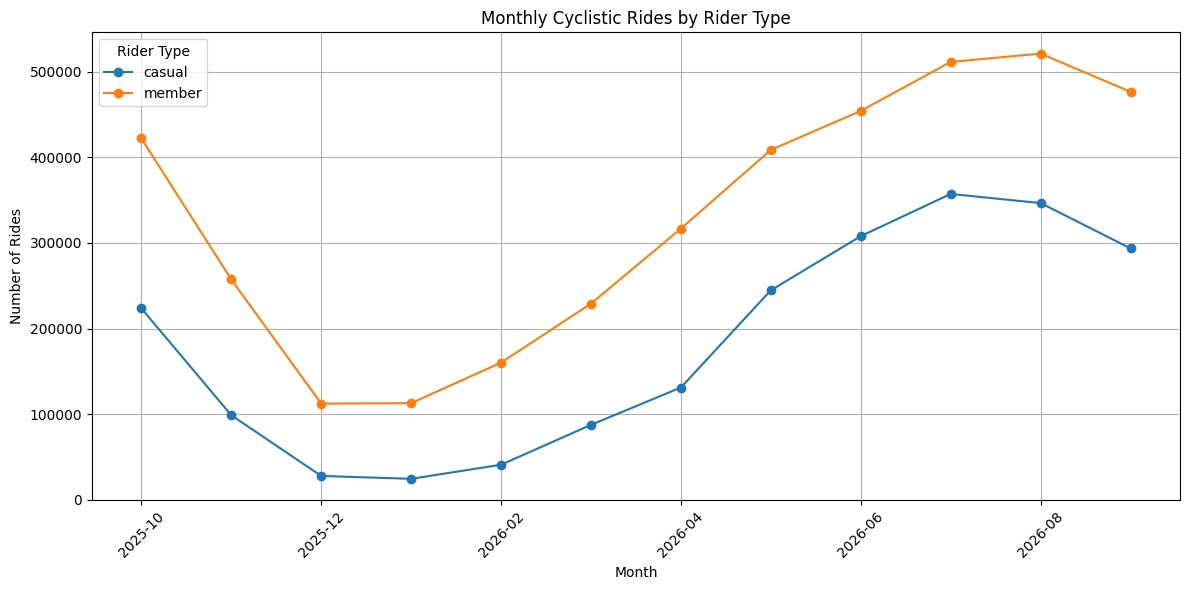

In [30]:
#Create your first full-year visualization
#Creating a line chart showing how monthly rides change for casual riders and annual members. This will be one of the visualizations you can include in your final case study.


import matplotlib.pyplot as plt

monthly_rides.plot(
    kind='line',
    marker='o',
    figsize=(12, 6)
)

plt.title('Monthly Cyclistic Rides by Rider Type')
plt.xlabel('Month')
plt.ylabel('Number of Rides')
plt.xticks(rotation=45)
plt.legend(title='Rider Type')
plt.grid(True)
plt.tight_layout()
plt.savefig('monthly_rides_by_rider_type.png', dpi=300, bbox_inches='tight')
plt.show()


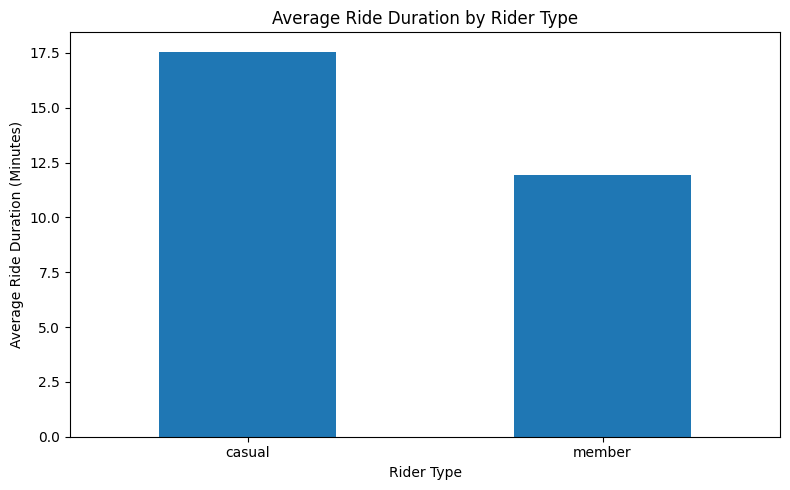

In [32]:

#Visualization 2: Average Ride Duration by Rider Type
#Create the chart

import matplotlib.pyplot as plt

avg_duration = df_analysis.groupby('member_casual')['ride_length_minutes'].mean()

avg_duration = avg_duration.reindex(['casual', 'member'])

avg_duration.plot(kind='bar', figsize=(8, 5))

plt.title('Average Ride Duration by Rider Type')
plt.xlabel('Rider Type')
plt.ylabel('Average Ride Duration (Minutes)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('average_ride_duration.png', dpi=300, bbox_inches='tight')
plt.show()

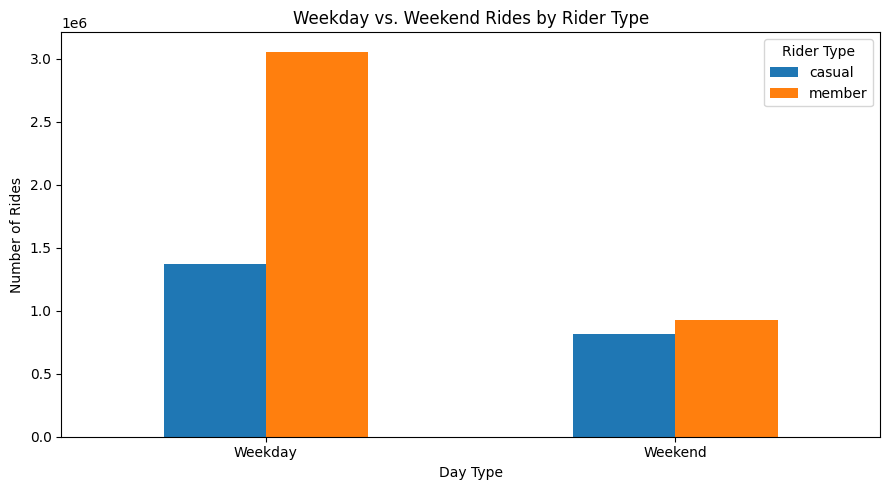

In [34]:
#Create the chart in Google Colab
#We can see a chart comparing weekday and weekend rides for casual riders and annual members.
import matplotlib.pyplot as plt

weekend_counts = df_analysis.groupby(
    ['day_type', 'member_casual']
).size().unstack(fill_value=0)

weekend_counts = weekend_counts.reindex(['Weekday', 'Weekend'])

weekend_counts.plot(kind='bar', figsize=(9, 5))

plt.title('Weekday vs. Weekend Rides by Rider Type')
plt.xlabel('Day Type')
plt.ylabel('Number of Rides')
plt.xticks(rotation=0)
plt.legend(title='Rider Type')
plt.tight_layout()
plt.savefig('weekday_weekend_rides.png', dpi=300, bbox_inches='tight')
plt.show()

In [35]:
# Final ride counts by rider type
final_ride_counts = df_analysis['member_casual'].value_counts()

print("Final date-filtered ride counts:")
print(final_ride_counts)

print("\nTotal rides:", len(df_analysis))

Final date-filtered ride counts:
member_casual
member    3981574
casual    2184772
Name: count, dtype: int64

Total rides: 6166346


In [36]:

# Recalculate ride duration using the final date-filtered dataset

duration_summary = df_analysis.groupby('member_casual')['ride_length_minutes'].agg(
    ride_count='count',
    average_minutes='mean',
    median_minutes='median'
)

print(duration_summary.round(2))


               ride_count  average_minutes  median_minutes
member_casual                                             
casual            2184772            17.56           10.75
member            3981574            11.92            8.51


In [37]:

# Recalculate weekday and weekend usage on the final dataset

day_type_counts = df_analysis.groupby(
    ['day_type', 'member_casual']
).size().unstack(fill_value=0)

day_type_counts = day_type_counts.reindex(['Weekday', 'Weekend'])

day_type_percent = day_type_counts.div(
    day_type_counts.sum(axis=0), axis=1
) * 100

print("RIDE COUNTS")
print(day_type_counts)

print("\nPERCENTAGE WITHIN EACH RIDER GROUP")
print(day_type_percent.round(2))


RIDE COUNTS
member_casual   casual   member
day_type                       
Weekday        1369786  3054917
Weekend         814986   926657

PERCENTAGE WITHIN EACH RIDER GROUP
member_casual  casual  member
day_type                     
Weekday          62.7   76.73
Weekend          37.3   23.27


In [38]:

# Final ride counts by day of the week

day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

rides_by_day = df_analysis.groupby(
    [df_analysis['started_at'].dt.day_name(), 'member_casual']
).size().unstack(fill_value=0)

rides_by_day = rides_by_day.reindex(day_order)

print(rides_by_day)

print("\nBusiest day for casual riders:",
      rides_by_day['casual'].idxmax(),
      "-", f"{rides_by_day['casual'].max():,}", "rides")

print("Busiest day for annual members:",
      rides_by_day['member'].idxmax(),
      "-", f"{rides_by_day['member'].max():,}", "rides")


member_casual  casual  member
started_at                   
Monday         251216  555584
Tuesday        249288  641038
Wednesday      254830  644595
Thursday       271742  628501
Friday         342710  585199
Saturday       464665  508489
Sunday         350321  418168

Busiest day for casual riders: Saturday - 464,665 rides
Busiest day for annual members: Wednesday - 644,595 rides


In [39]:

# Verify monthly totals using the final date-filtered dataset

monthly_check = df_analysis.groupby(
    [df_analysis['started_at'].dt.to_period('M').astype(str),
     'member_casual']
).size().unstack(fill_value=0)

monthly_check['Total'] = monthly_check.sum(axis=1)

print(monthly_check)

print("\nTotal rides across all months:",
      monthly_check['Total'].sum())

print("\nTotal casual rides:",
      df_analysis['member_casual'].eq('casual').sum())

print("Total member rides:",
      df_analysis['member_casual'].eq('member').sum())


member_casual  casual  member   Total
started_at                           
2025-10        223569  421921  645490
2025-11         98871  257292  356163
2025-12         28005  112415  140420
2026-01         24656  112933  137589
2026-02         41088  160251  201339
2026-03         87631  229121  316752
2026-04        131223  316675  447898
2026-05        244654  408510  653164
2026-06        307873  454025  761898
2026-07        357121  511205  868326
2026-08        346473  520948  867421
2026-09        293608  476278  769886

Total rides across all months: 6166346

Total casual rides: 2184772
Total member rides: 3981574


In [40]:

# Final summary for the Cyclistic case study

print("=== TOTAL RIDES ===")
print(df_analysis["member_casual"].value_counts())
print("\nTotal:", len(df_analysis))

print("\n=== RIDE DURATION (MINUTES) ===")
print(
    df_analysis.groupby("member_casual")["ride_length_minutes"]
    .agg(["count", "mean", "median"])
    .round(2)
)

print("\n=== WEEKDAY VS WEEKEND ===")
print(day_type_counts)
print("\nPercentage within each rider group:")
print(day_type_percent.round(2))

print("\n=== RIDES BY DAY OF WEEK ===")
print(rides_by_day)

print("\n=== MONTHLY RIDES ===")
print(monthly_check)

print("\n=== CLEANED DATA CHECKS ===")
print("Missing ride IDs:", df_analysis["ride_id"].isna().sum())
print("Duplicate ride IDs:", df_analysis["ride_id"].duplicated().sum())
print("Invalid durations:",
      (df_analysis["ride_length_minutes"] <= 0).sum())


=== TOTAL RIDES ===
member_casual
member    3981574
casual    2184772
Name: count, dtype: int64

Total: 6166346

=== RIDE DURATION (MINUTES) ===
                 count   mean  median
member_casual                        
casual         2184772  17.56   10.75
member         3981574  11.92    8.51

=== WEEKDAY VS WEEKEND ===
member_casual   casual   member
day_type                       
Weekday        1369786  3054917
Weekend         814986   926657

Percentage within each rider group:
member_casual  casual  member
day_type                     
Weekday          62.7   76.73
Weekend          37.3   23.27

=== RIDES BY DAY OF WEEK ===
member_casual  casual  member
started_at                   
Monday         251216  555584
Tuesday        249288  641038
Wednesday      254830  644595
Thursday       271742  628501
Friday         342710  585199
Saturday       464665  508489
Sunday         350321  418168

=== MONTHLY RIDES ===
member_casual  casual  member   Total
started_at                   

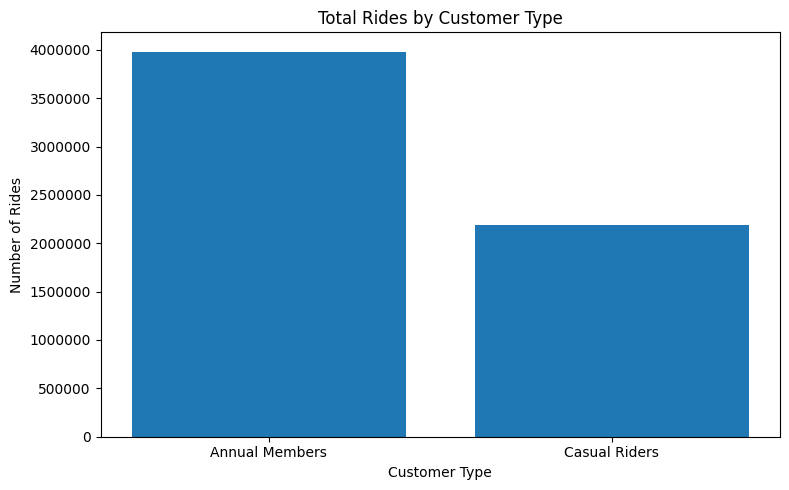

In [41]:
import matplotlib.pyplot as plt

rider_counts = df_analysis["member_casual"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(
    ["Annual Members", "Casual Riders"],
    [
        rider_counts.get("member", 0),
        rider_counts.get("casual", 0)
    ]
)

plt.title("Total Rides by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Number of Rides")
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()

plt.savefig("total_rides_by_customer_type.png", dpi=300)
plt.show()